In [1]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib as mpl
from neuron import h
import multiprocessing as mp
from scipy.signal import savgol_filter
# from scipy.interpolate import sintline
import yaml
import seaborn as sns
import itertools
from matplotlib.ticker import ScalarFormatter

--No graphics will be displayed.


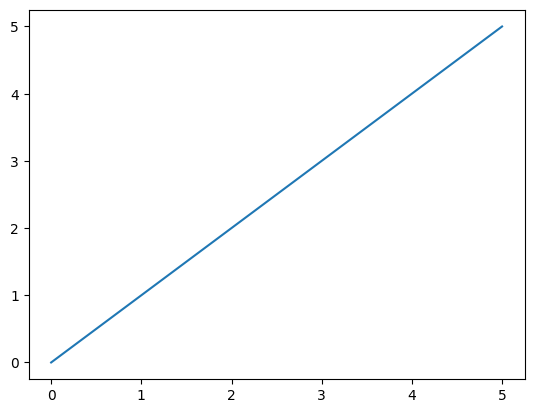

In [5]:
plt.plot([0,1,2,3,4,5], [0,1,2,3,4,5], linestyle='-', marker='')

In [2]:
seed = 34657845

In [3]:
stimpar = {
    "dur": 0.26,
    "pip": 0.1,
    "start": [0.1],
    "baseline": [50, 150],
    "response": [150, 250],
}

In [4]:
f = 22000
db = 60

In [5]:
stim = sound.TonePip(
    rate=100e3,
    duration=stimpar["dur"],
    f0=f,
    dbspl=db,
    ramp_duration=2.5e-3,
    pip_duration=stimpar["pip"],
    pip_start=stimpar["start"],
)

In [6]:
sgc_pop = populations.SGC()
sgc_cfs = sgc_pop._get_cf_array(species='mouse')

In [7]:
sub_sgc_cfs = sgc_cfs[-100:]

In [8]:
sub_ohcs = []
for cf in sub_sgc_cfs:
    ohc = np.piecewise(cf, [cf < 38500, (38500 <= cf) & (cf < 39500), 39500 <= cf], [1, 0.8, 0.6])
    sub_ohcs.append(ohc)
np.array(sub_ohcs)

array([1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. ,
       1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 0.8, 0.8, 0.8, 0.8, 0.8,
       0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8,
       0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8,
       0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8,
       0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.6, 0.6, 0.6, 0.6,
       0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6,
       0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

In [9]:
bounds = np.array([15, 21, 28, 34, 38])*1e3

conds_list = []

for i in range(len(bounds)):

    if i == 0:
        conds_list.append(f'cf < {bounds[i]}')

    if i < len(bounds)-1:
        conds_list.append(f'{bounds[i]} <= cf and cf < {bounds[i+1]}')
    else:
        conds_list.append(f'{bounds[i]} <= cf')

conds_list

['cf < 15000.0',
 '15000.0 <= cf and cf < 21000.0',
 '21000.0 <= cf and cf < 28000.0',
 '28000.0 <= cf and cf < 34000.0',
 '34000.0 <= cf and cf < 38000.0',
 '38000.0 <= cf']

In [10]:
conds_list = []

for i in range(len(bounds)):

    if i == 0:
        conds_list.append(lambda x, b=bounds[i]: x < b)

    if i < len(bounds)-1:
        conds_list.append(lambda x, lo=bounds[i], hi=bounds[i+1]: (lo <= x) & (x < hi))
    else:
        conds_list.append(lambda x, b=bounds[i]: b <= x)

conds_list

[<function __main__.<lambda>(x, b=np.float64(15000.0))>,
 <function __main__.<lambda>(x, lo=np.float64(15000.0), hi=np.float64(21000.0))>,
 <function __main__.<lambda>(x, lo=np.float64(21000.0), hi=np.float64(28000.0))>,
 <function __main__.<lambda>(x, lo=np.float64(28000.0), hi=np.float64(34000.0))>,
 <function __main__.<lambda>(x, lo=np.float64(34000.0), hi=np.float64(38000.0))>,
 <function __main__.<lambda>(x, b=np.float64(38000.0))>]

In [11]:
ohcs = [1, 0.9, 0.8, 0.7, 0.6, 0.5]

In [12]:
for i, f in enumerate(conds_list):
    print(i, f(cf))

print([f(cf) for f in conds_list])
print(np.piecewise(cf, [f(cf) for f in conds_list], ohcs))

0 False
1 False
2 False
3 False
4 False
5 True
[np.False_, np.False_, np.False_, np.False_, np.False_, np.True_]
0.5


In [13]:
dohc = np.gradient(np.piecewise(sgc_cfs, [f(sgc_cfs) for f in conds_list], ohcs))

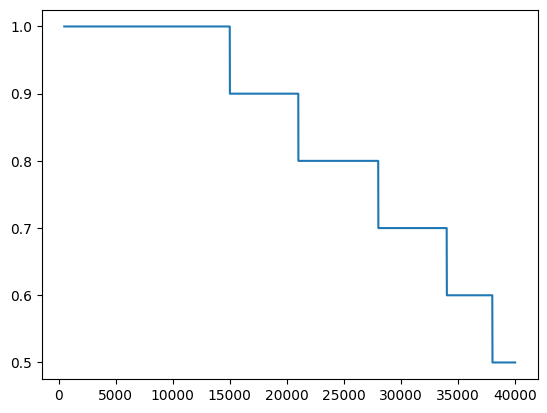

In [14]:
plt.plot(sgc_cfs, np.piecewise(sgc_cfs, [f(sgc_cfs) for f in conds_list], ohcs))

In [15]:
smin = 0
smax = 1
f50 = 25000
width = 3000

survival = smin + ((smax - smin) / (1 + np.exp((sgc_cfs - f50)/width)))

In [16]:
def log_decay(cf, freq_half, width, smin=0, smax=1):
    return smin + ((smax - smin) / (1 + np.exp((cf - freq_half)/width)))

In [17]:
cohcs = log_decay(sgc_cfs, 17*1e3, 2.5*1e3, smin=0.2)
cihcs = log_decay(sgc_cfs, 22.1*1e3, 3.8*1e3, smin=0.5)
sgn_losses = log_decay(sgc_cfs, 18.5*1e3, 3.4*1e3, smin=0.3)


In [20]:
cohc_decay = log_decay

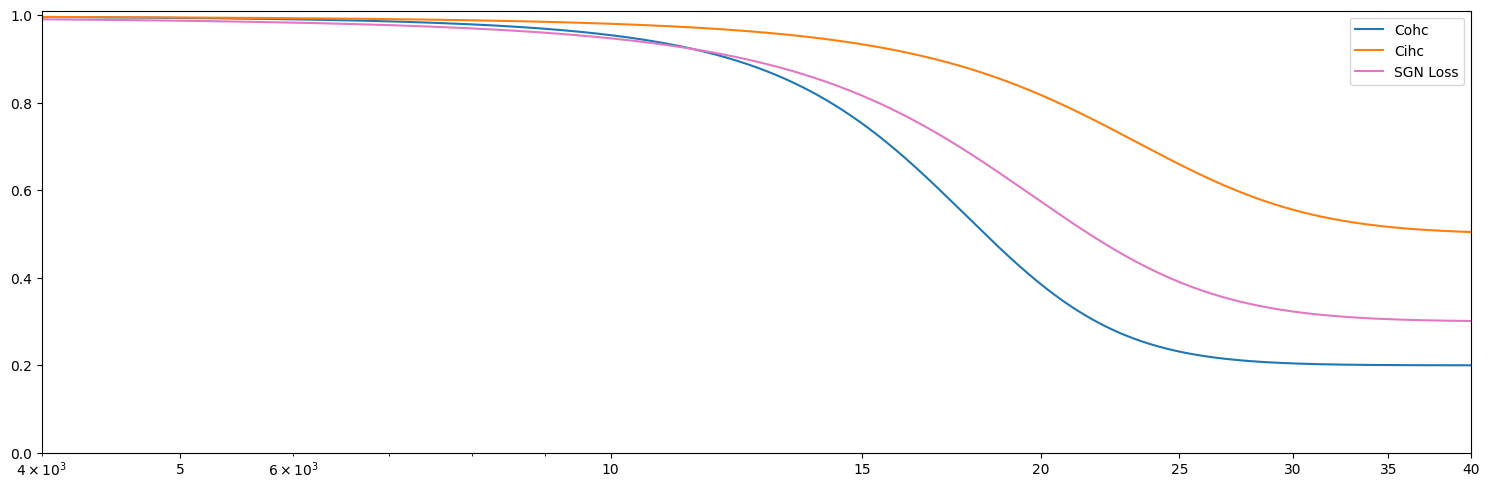

In [18]:
fig, axs = plt.subplots(1,1,figsize=(15,5))

# axs.axvspan(f50-width, f50+width, color='grey', alpha=0.3)
# axs.axvline(f50)
axs.plot(sgc_cfs, cohcs, color='tab:blue', label='Cohc')
axs.plot(sgc_cfs, cihcs, color='tab:orange', label='Cihc')
axs.plot(sgc_cfs, sgn_losses, color='tab:pink', label='SGN Loss')

axs.legend(loc='upper right')

axs.set_xscale('log')
axs.xaxis.set_major_formatter(ScalarFormatter())
axs.set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs.set_xticklabels([5, 10, 15, 20, 25, 30, 35, 40])
axs.set_xlim([4000, 40000])
axs.set_ylim([0,1.01])
fig.tight_layout()

In [19]:
sgn_lost = []
for sgn_loss in sgn_losses:
    sgn_lost.append(1 if random.random() < sgn_loss else 0)
counts = np.unique(np.array(sgn_lost), return_counts=True)
counts[1][0]/len(sgn_lost), counts[1][1]/len(sgn_lost)

(np.float64(0.13640389725420726), np.float64(0.8635961027457927))